In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os


In [45]:
data = pd.read_csv("données/LucasBenjamin_664b368abdac8e709d4ff17d.csv", skiprows=1, index_col=3)

## Filtering du dataframe pour 1 sujet

In [3]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered = df_filtered.dropna(subset=["final_angle"])


In [4]:
df_filtered

,trial_rt,presented_angles,stimulus_rotations,final_angle,target,score
0,2305.0,"[186.3297408056, 172.4988425288, 115.6656248854]","[-45.0, -45.0, 45.0]",-24.646771,143.138643,6
1,1958.0,"[98.0630303799, 193.2006295208, 49.6275131924,...","[45.0, -45.0, 45.0, -45.0, 0.0, -45.0, -45.0]",-13.958290,132.662918,0
2,2380.0,"[34.0026636518, 78.5751250026, 144.2219944684,...","[45.0, 45.0, 0.0, 0.0, 0.0]",146.390631,130.568813,6
3,1969.0,"[86.8257191556, 137.819327054, 157.3072000846]","[0.0, -45.0, -45.0]",52.776429,97.281009,0
4,1735.0,"[99.1813592646, 91.1827684021, -22.5187808445,...","[-45.0, -45.0, 45.0, 0.0, 45.0, -45.0, -45.0]",209.237852,31.195139,10
...,...,...,...,...,...,...
195,2426.0,[218.4099821053],[-45.0],-9.130176,173.409982,10
196,2508.0,[195.9147529961],[0.0],15.718573,15.914753,10
197,1822.0,"[159.3437590786, 153.8696178772, 90.66764952, ...","[-45.0, -45.0, 0.0, 0.0, 0.0]",-79.343152,105.643527,10
198,1814.0,[74.993424937],[-45.0],-59.349332,29.993425,0


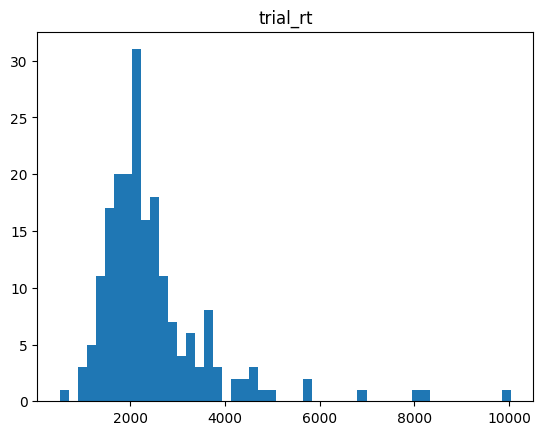

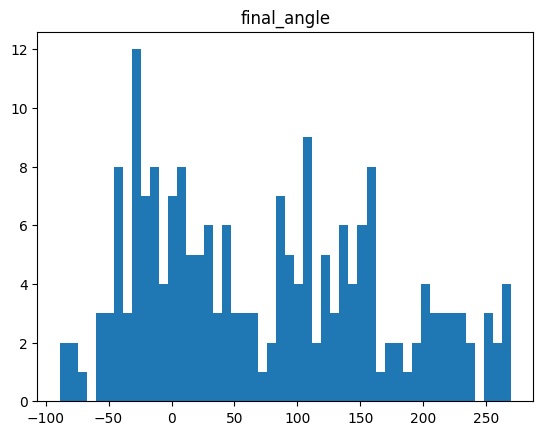

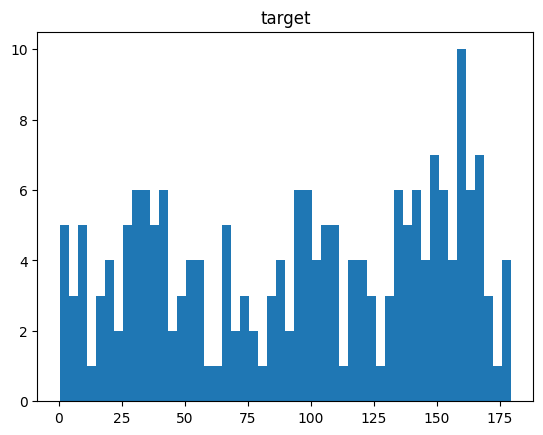

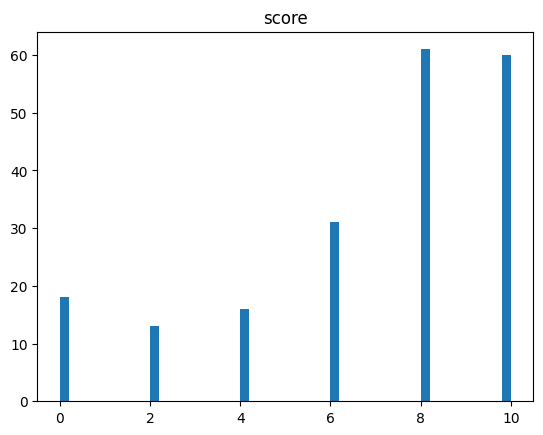

In [5]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

## Filtrage des données pour tous

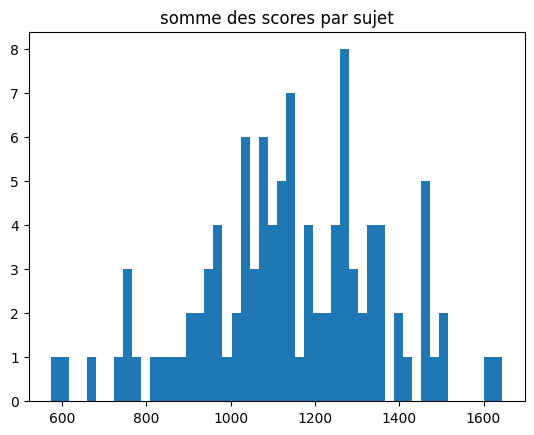

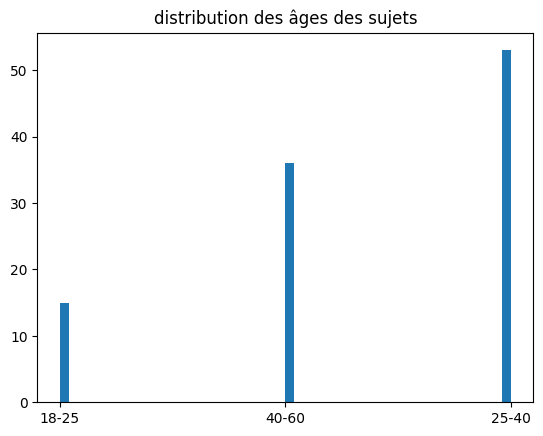

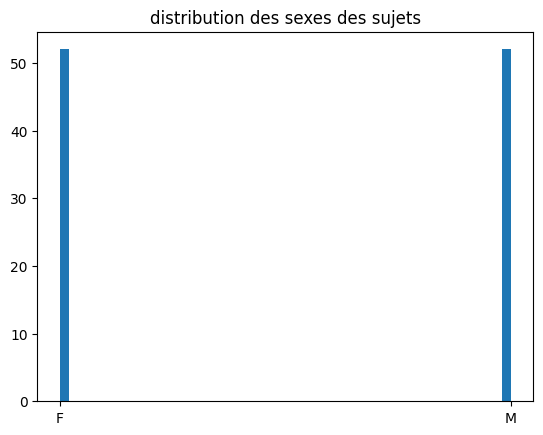

In [54]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sexe_tot = []
    for dfs in dfs :     
        age = dfs['responses'][dfs["trial_type"]== 'survey-dropdown'][2][6:11]
        sexe = dfs['responses'][dfs["trial_type"]== 'survey-dropdown'][2][18]
        age_tot = age_tot + [age]
        sexe_tot = sexe_tot + [sexe]
        
        df_filtered = dfs[dfs["stimulus_rotations"].notna()]
        df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
        df_filtered.reset_index(drop=True, inplace=True)
        df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['score'] = df_filtered['score'].astype(int)
        df_filtered = df_filtered.dropna(subset=["final_angle"])
        score_sum.append(df_filtered["score"].sum())
        
    return score_sum, age, age_tot, sexe, sexe_tot


plt.hist(data_sujets(dfs)[0], bins=50)
plt.title("somme des scores par sujet")
plt.show()

plt.hist(data_sujets(dfs)[2], bins=50)
plt.title("distribution des âges des sujets")
plt.show()

plt.hist(data_sujets(dfs)[4], bins=50)
plt.title(f"distribution des sexes des sujets ()")
plt.show()

In [68]:
print("il y a",data_sujets(dfs)[4].count('F'), "femmes")
print("il y a",data_sujets(dfs)[4].count('M'), 'hommes')

il y a 52 femmes
il y a 52 hommes


In [70]:
print("il y a",data_sujets(dfs)[2].count('18-25'), "personnes qui ont entre 18 et 25 ans")
print("il y a",data_sujets(dfs)[2].count('25-40'), 'personnes qui ont entre 25 et 40 ans')
print("il y a",data_sujets(dfs)[2].count('40-60'), 'personnes qui ont entre 40 et 60 ans')

il y a 15 personnes qui ont entre 18 et 25 ans
il y a 53 personnes qui ont entre 25 et 40 ans
il y a 36 personnes qui ont entre 40 et 60 ans
